In [11]:
import os
import pandas as pd

import spacy
import nltk
from dataset_wo_config_files import read_conll_file, make_dict_of_sentences_no_cross
import seaborn as sns
import matplotlib.pyplot as plt


In [12]:
sp = spacy.load('en_core_web_sm')
spacy_stopwords = sp.Defaults.stop_words

In [13]:
def get_sentences_by_split(dataset_folder, split_name):
    docs_path = os.path.join(dataset_folder + split_name + '/', 'dataset.conll')
    documents, topics = read_conll_file(docs_path)
    sentences_dict = make_dict_of_sentences_no_cross(documents)

    all_sentences = []
    for doc in sentences_dict.values():
        for sentence in doc.values():
            sentence_str = ' '.join([token[2] for token in sentence])
            all_sentences.append(sentence_str)

    return all_sentences

In [14]:
#ECB+:
common_data_folder = "../CDCR/data/"
dataset_name = 'ECBplus-prep'
dataset_folder = f"{common_data_folder}{dataset_name}/output_data/"
split_name = 'train'
ecbplus_sentences_train = get_sentences_by_split(dataset_folder, split_name)

split_name = 'test'
ecbplus_sentences_test = get_sentences_by_split(dataset_folder, split_name)

split_name = 'val'
ecbplus_sentences_val = get_sentences_by_split(dataset_folder, split_name)

ecbplus_sentences = ecbplus_sentences_train + ecbplus_sentences_test + ecbplus_sentences_val


In [15]:
#NewsWCL50:
dataset_name = 'NewsWCL50-prep'
dataset_folder = f"{common_data_folder}{dataset_name}/output_data/"
split_name = 'train'
newswcl50_sentences_train = get_sentences_by_split(dataset_folder, split_name)

split_name = 'test'
newswcl50_sentences_test = get_sentences_by_split(dataset_folder, split_name)

split_name = 'val'
newswcl50_sentences_val = get_sentences_by_split(dataset_folder, split_name)

newswcl50_sentences = newswcl50_sentences_train + newswcl50_sentences_test + newswcl50_sentences_val


In [16]:
# sentences_dict['1/1ecb/1'][2]
# This is going to be key to reproduce CLCOREF

In [17]:
# I need to squeeze the dictionary to create a list of sentences from it. First attempt via 
# Inefficient for loop

In [23]:
# Function to get top tokens
def get_top_tokens(sentences_list, num_tokens=10000):
    # Handle NaN values by converting them to an empty string
    sentences_list = [str(sent) for sent in sentences_list if pd.notna(sent)]
    
    # Join the sentences and tokenize
    tokens = nltk.word_tokenize(" ".join(sentences_list))

    text_without_stopword = [word for word in tokens if word not in spacy_stopwords]

    # Create a frequency distribution of the tokens
    freq_dist = nltk.FreqDist(text_without_stopword)

    # Retrieve the top N most frequent tokens
    top_tokens = freq_dist.most_common(num_tokens)

    # Extract just the tokens (without frequencies)
    top_tokens_only = set([token[0] for token in top_tokens])

    return top_tokens_only


In [24]:
top_10000_ecbplus = get_top_tokens(ecbplus_sentences)
top_10000_newswcl50 = get_top_tokens(newswcl50_sentences)

In [27]:
def jaccard_similarity(set1, set2):
    intersection_size = len(set1.intersection(set2))
    union_size = len(set1.union(set2))
    
    if union_size == 0:
        return 0  # Avoid division by zero
    
    similarity = intersection_size / union_size
    return similarity

In [28]:
jaccard_similarity(top_10000_ecbplus,top_10000_newswcl50)

0.2590011614401858

In [29]:
import pandas as pd

# Specify the directory containing the CSV files
directory_path = r'c:\Users\sago\Documents\GitHub\MBIB\datasets\mbib-aggregated'

# List of CSV files
csv_files = [
    "cognitive-bias.csv",
    "fake-news.csv",
    "gender-bias.csv",
    "hate-speech.csv",
    "linguistic-bias.csv",
    "political-bias.csv",
    "racial-bias.csv",
    "text-level-bias.csv"
]

# Create an empty dictionary to store DataFrames
dataframes_dict = {}

# Load each CSV file into a DataFrame and store in the dictionary
for file_name in csv_files:
    file_path = os.path.join(directory_path, file_name)
    df = pd.read_csv(file_path)
    # Remove file extension to use as the dictionary key
    key = os.path.splitext(file_name)[0]
    dataframes_dict[key] = df

# Now dataframes_dict contains all DataFrames with keys as file names (without extension)


In [38]:
# Create a new dictionary for processed DataFrames using get_top_tokens function
processed_dataframes_dict = {}

# Process each DataFrame and store the result in the new dictionary
for key, df in dataframes_dict.items():
    sentences_list = df['text'].tolist()
    top_tokens = get_top_tokens(sentences_list)
    processed_dataframes_dict[key] = top_tokens

processed_dataframes_dict["ECBplus"] = set(top_10000_ecbplus)
processed_dataframes_dict["NewsWCL50"] = set(top_10000_newswcl50)

processed_dataframes_dict.pop('fake-news',None)
processed_dataframes_dict.pop('racial-bias',None)

{'senator',
 'universities',
 'organization',
 'bloody',
 'Development',
 'Creflo',
 'protest',
 'Atlantic',
 'transferred',
 'horrible',
 'Because',
 'pictured',
 'global',
 'intimidation',
 'proposition',
 'requirecondom',
 'Ali',
 'Prads',
 'Sanford',
 '287',
 'handsome',
 'fence',
 'Warner',
 'blasphemous',
 'youth',
 'Meek',
 'cost',
 'counterparts',
 'admire',
 'Oswald',
 'Akin',
 'advice',
 'Suspect',
 'Leafs',
 'HB',
 'unpopular',
 'SaysCongressman',
 'overtesting',
 'takes',
 'liens',
 'aboard',
 'Treasurer',
 'old',
 'POWs',
 'basic',
 'tanks',
 'target',
 'witnessed',
 'cramps',
 'pronounced',
 'reputation',
 'kosher',
 'window',
 'contact',
 'exempt',
 'immigrate',
 'swim',
 'solutions',
 'Barrett',
 'generous',
 'describes',
 'lane',
 'person',
 'surgeries',
 'amidst',
 'usage',
 'counting',
 'poses',
 'Kenosha',
 'DEVELOPING',
 'trans',
 'groundbreaking',
 'interviewed',
 'Ray',
 'redefine',
 'imams',
 'chase',
 'happen',
 'chairs',
 'Browns',
 'pour',
 'FRated',
 'sadnes

In [35]:
processed_dataframes_dict.keys()

dict_keys(['cognitive-bias', 'fake-news', 'gender-bias', 'hate-speech', 'linguistic-bias', 'political-bias', 'racial-bias', 'text-level-bias', 'ECBplus', 'NewsWCL50'])

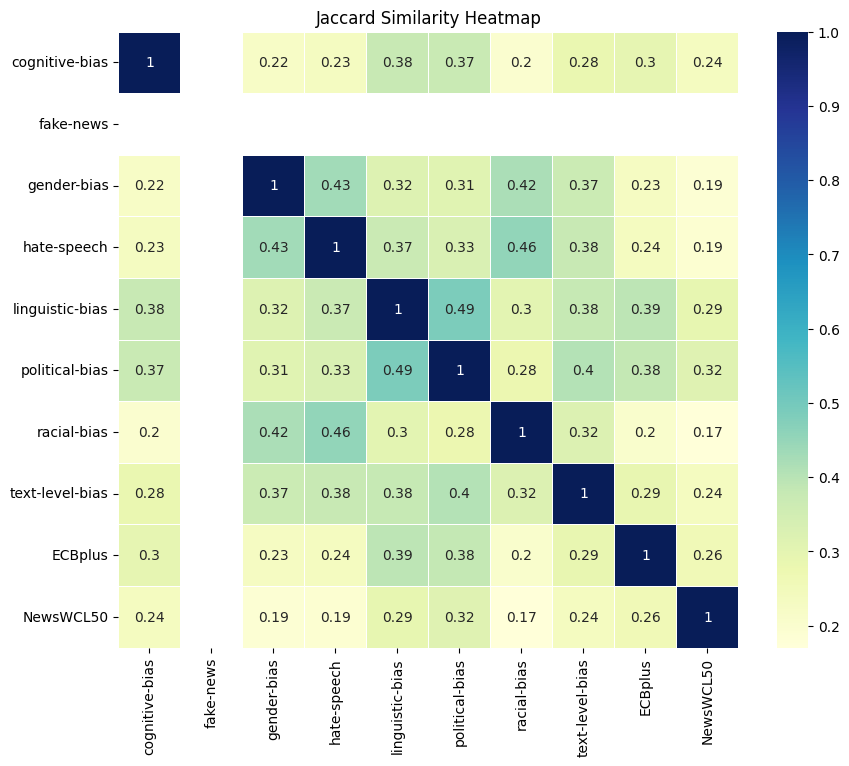

In [37]:

# Calculate Jaccard similarity for all pairs in processed_dataframes_dict
similarity_matrix = pd.DataFrame(index=processed_dataframes_dict.keys(), columns=processed_dataframes_dict.keys())

for key1, set1 in processed_dataframes_dict.items():
    if key1!='fake-news':
        for key2, set2 in processed_dataframes_dict.items():
            if key2!='fake-news':
                similarity_matrix.loc[key1, key2] = jaccard_similarity(set1, set2)

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5)
plt.title("Jaccard Similarity Heatmap")
plt.show()

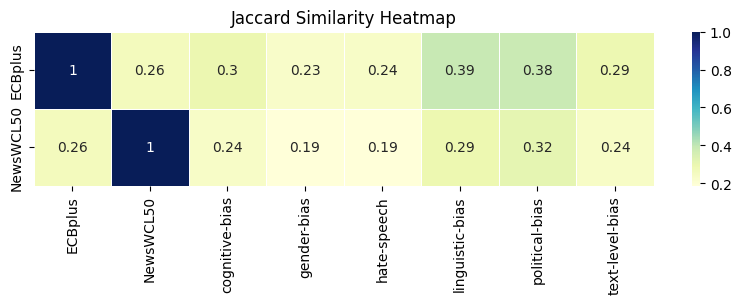

In [51]:
# Extract keys for rows and columns
rows = ['ECBplus', 'NewsWCL50']
columns = ['ECBplus', 'NewsWCL50']
columns.extend([key for key in processed_dataframes_dict if key not in rows])



# Calculate Jaccard similarity for specified pairs
similarity_matrix = pd.DataFrame(index=rows, columns=columns)

for row_key in rows:
    for col_key in columns:
        similarity_matrix.loc[row_key, col_key] = jaccard_similarity(
            processed_dataframes_dict[row_key], processed_dataframes_dict[col_key]
        )

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 2))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5, square=False)
plt.title("Jaccard Similarity Heatmap")
plt.show()